# Module 18 — Sampling, MCMC and Generative Models

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or keep
it open alongside. Every section mirrors a numbered section of the guide. We start with the exact samplers
that turn uniform random numbers into any distribution (inverse CDF, cumulative sums, Box–Muller,
reparameterisation), then correct samples from a convenient proposal with rejection and importance
sampling, build Markov chains whose long-run distribution is a target we choose (Metropolis–Hastings,
Gibbs, Langevin dynamics), turn inference into optimisation with the ELBO and a NumPy variational
autoencoder, and finish with a one-dimensional diffusion model — forward noising, the closed-form marginal,
and reverse sampling with both the exact score and a small trained denoiser — and the Fréchet distance
used to evaluate generative models.

Everything is plain NumPy/SciPy, built from the formulas in the guide; library calls appear only to confirm
the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Why sampling: an integral becomes an average

The Monte Carlo estimator $\hat\mu_n = \frac1n\sum_i f(X_i)$ of $\mu = \mathbb{E}_p[f(X)]$ is unbiased
with standard deviation $\sigma_f/\sqrt{n}$, whatever the dimension. We test it on a case with a known
answer: $X \sim \mathcal{N}(0, 1)$, $f(x) = e^{-x^2}$, for which $\mathbb{E}[f(X)] = 1/\sqrt{3}$.
Repeating the whole experiment 200 times for each $n$ shows the error falling as $1/\sqrt{n}$.

Monte Carlo estimate with n = 10,000: 0.5784   exact 1/sqrt(3) = 0.5774
sample sd of f(X) = 0.3402  ->  standard error = 0.0034


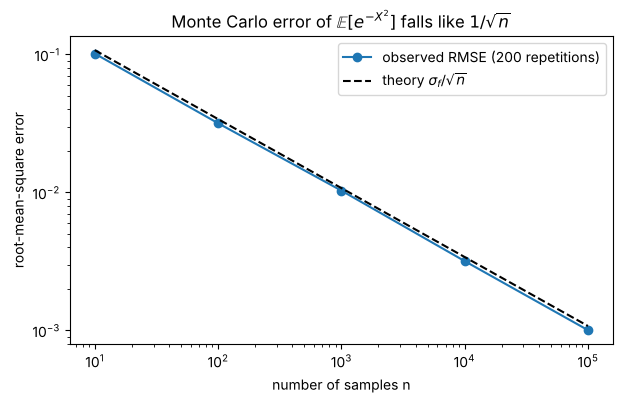

n =      10: RMSE 0.10150
n =     100: RMSE 0.03175
n =    1000: RMSE 0.01031
n =   10000: RMSE 0.00318
n =  100000: RMSE 0.00100


In [2]:
exact = 1 / np.sqrt(3)
x = rng.standard_normal(10_000)
f = np.exp(-x ** 2)
print(f"Monte Carlo estimate with n = 10,000: {f.mean():.4f}   exact 1/sqrt(3) = {exact:.4f}")
print(f"sample sd of f(X) = {f.std():.4f}  ->  standard error = {f.std() / np.sqrt(len(f)):.4f}")

ns = np.array([10, 100, 1_000, 10_000, 100_000])
rmse = np.array([np.sqrt(np.mean([(np.exp(-rng.standard_normal(n) ** 2).mean() - exact) ** 2
                                  for _ in range(200)])) for n in ns])
plt.loglog(ns, rmse, "o-", label="observed RMSE (200 repetitions)")
plt.loglog(ns, f.std() / np.sqrt(ns), "k--", label=r"theory $\sigma_f/\sqrt{n}$")
plt.xlabel("number of samples n"); plt.ylabel("root-mean-square error")
plt.title(r"Monte Carlo error of $\mathbb{E}[e^{-X^2}]$ falls like $1/\sqrt{n}$"); plt.legend(); plt.show()
for n, r in zip(ns, rmse):
    print(f"n = {n:>7d}: RMSE {r:.5f}")

Every factor of 100 in $n$ buys one more decimal digit. The whole module is about the two words the
estimator takes for granted — "$X_i \sim p$" — which are easy for a Gaussian and hard for a posterior
or an image distribution.

## 2. Exact samplers from uniform random numbers

**Inverse CDF:** if $U \sim \text{Uniform}(0,1)$ then $X = F^{-1}(U)$ has CDF $F$. For the Exponential($\lambda$),
$X = -\ln(1 - U)/\lambda$. **Discrete:** return the first index whose cumulative probability exceeds $U$
(`np.searchsorted` on the cumulative sums). **Box–Muller:** $Z_1 = \sqrt{-2\ln U_1}\cos 2\pi U_2$,
$Z_2 = \sqrt{-2\ln U_1}\sin 2\pi U_2$ are independent standard normals. **Reparameterisation:**
$X = \mu + \sigma Z \sim \mathcal{N}(\mu, \sigma^2)$ — the randomness lives in $Z$, the parameters enter
through a differentiable formula.

inverse CDF, u = 0.3 -> x = 0.1783;  u = 0.9 -> x = 1.1513
Exponential(2): sample mean 0.4923 (exact 0.5), sample var 0.2396 (exact 0.25)
cumulative sums [0.2 0.7 1. ];  u = 0.65 -> category 1
discrete sampler frequencies [0.2051 0.4998 0.295 ] vs p = [0.2 0.5 0.3]
Box-Muller with u1 = 0.5, u2 = 0.25: R = 1.1774, z1 = 0, z2 = 1.1774
Box-Muller normals: mean -0.0035, var 0.9847, P(|Z| > 1.96) = 0.0485 (exact 0.05)
3 + 2 Z: mean 2.9930, sd 1.9846


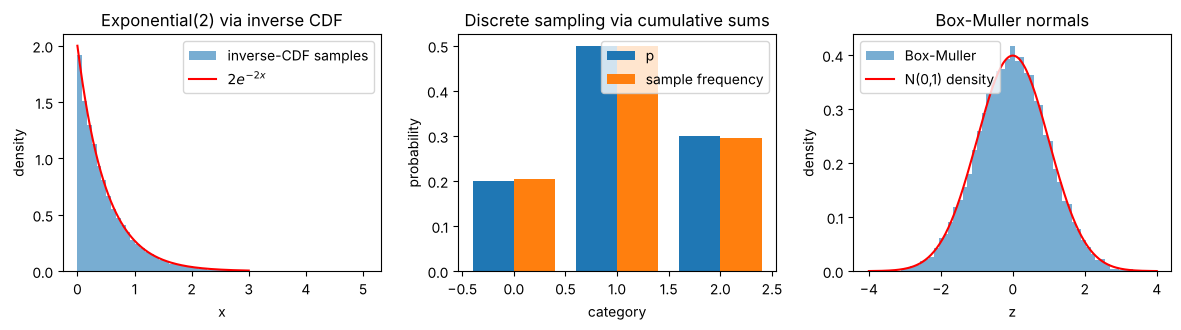

In [3]:
n = 20_000
u = rng.random(n)

# --- inverse CDF for the Exponential(lambda = 2)
lam = 2.0
x_exp = -np.log(1 - u) / lam
print(f"inverse CDF, u = 0.3 -> x = {-np.log(1 - 0.3) / lam:.4f};  u = 0.9 -> x = {-np.log(1 - 0.9) / lam:.4f}")
print(f"Exponential(2): sample mean {x_exp.mean():.4f} (exact 0.5), sample var {x_exp.var():.4f} (exact 0.25)")

# --- discrete sampling by cumulative sums
p = np.array([0.2, 0.5, 0.3])
cdf = np.cumsum(p)
k = np.searchsorted(cdf, u)                 # smallest k with cdf[k] >= u
freq = np.bincount(k, minlength=3) / n
print(f"cumulative sums {cdf};  u = 0.65 -> category {np.searchsorted(cdf, 0.65)}")
print(f"discrete sampler frequencies {freq.round(4)} vs p = {p}")

# --- Box-Muller
u1, u2 = rng.random(n // 2), rng.random(n // 2)
r = np.sqrt(-2 * np.log(u1))
z = np.concatenate([r * np.cos(2 * np.pi * u2), r * np.sin(2 * np.pi * u2)])
print(f"Box-Muller with u1 = 0.5, u2 = 0.25: R = {np.sqrt(-2 * np.log(0.5)):.4f}, z1 = 0, z2 = {np.sqrt(-2 * np.log(0.5)):.4f}")
print(f"Box-Muller normals: mean {z.mean():.4f}, var {z.var():.4f}, P(|Z| > 1.96) = {np.mean(np.abs(z) > 1.96):.4f} (exact 0.05)")

# --- reparameterisation: N(3, 2^2) from the same z
x_rep = 3 + 2 * z
print(f"3 + 2 Z: mean {x_rep.mean():.4f}, sd {x_rep.std():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
grid = np.linspace(0, 3, 200)
axes[0].hist(x_exp, bins=60, density=True, alpha=0.6, label="inverse-CDF samples")
axes[0].plot(grid, lam * np.exp(-lam * grid), "r", label=r"$2e^{-2x}$")
axes[0].set_xlabel("x"); axes[0].set_ylabel("density"); axes[0].set_title("Exponential(2) via inverse CDF"); axes[0].legend()
axes[1].bar(np.arange(3) - 0.2, p, width=0.4, label="p")
axes[1].bar(np.arange(3) + 0.2, freq, width=0.4, label="sample frequency")
axes[1].set_xlabel("category"); axes[1].set_ylabel("probability"); axes[1].set_title("Discrete sampling via cumulative sums"); axes[1].legend()
grid = np.linspace(-4, 4, 200)
axes[2].hist(z, bins=60, density=True, alpha=0.6, label="Box-Muller")
axes[2].plot(grid, stats.norm.pdf(grid), "r", label="N(0,1) density")
axes[2].set_xlabel("z"); axes[2].set_ylabel("density"); axes[2].set_title("Box-Muller normals"); axes[2].legend()
plt.tight_layout(); plt.show()

Three different distributions, one source of randomness: a stream of uniforms. The discrete sampler is
exactly what `rng.choice(3, p=p)` does, and what a language model's decoder does over a 100,000-word
vocabulary after the softmax. The reparameterised draw `3 + 2 * z` is the formula a VAE differentiates
through in Section 9.

**Try it yourself:** replace `-np.log(1 - u)` by `-np.log(u)` — the histogram does not change, because
$1 - U$ is also uniform. Then sample a Uniform(2, 5) and a Cauchy ($F^{-1}(u) = \tan(\pi(u - 1/2))$) by
inverse CDF and look at their sample means as $n$ grows.

## 3. Rejection sampling: Beta(2, 5) under a uniform envelope

Target $p(x) = 30\,x(1-x)^4$ on $[0, 1]$, proposal $q = \text{Uniform}(0,1)$. The smallest valid envelope
constant is the maximum of $p$, reached at $x^* = 0.2$: $M = p(0.2) = 2.4576$. Propose $x \sim q$,
$u \sim \text{Uniform}(0, 1)$, accept if $u \le p(x)/(Mq(x))$. The acceptance rate is $1/M \approx 0.407$ and
accepted samples have density exactly $p$ — the picture below is the proof: dots are uniform under the
envelope, and the kept dots are uniform under $p$.

envelope constant M = 2.4576  ->  predicted acceptance rate 1/M = 0.4069
observed acceptance rate 0.4059  (40593 of 100000 proposals kept)
mean of accepted samples 0.2861 (exact 2/7 = 0.2857),  var 0.0256 (exact 0.0255)
single proposals: x = 0.5, u = 0.5 -> ratio 0.381 -> rejected;  x = 0.15, u = 0.5 -> ratio 0.956 -> accepted


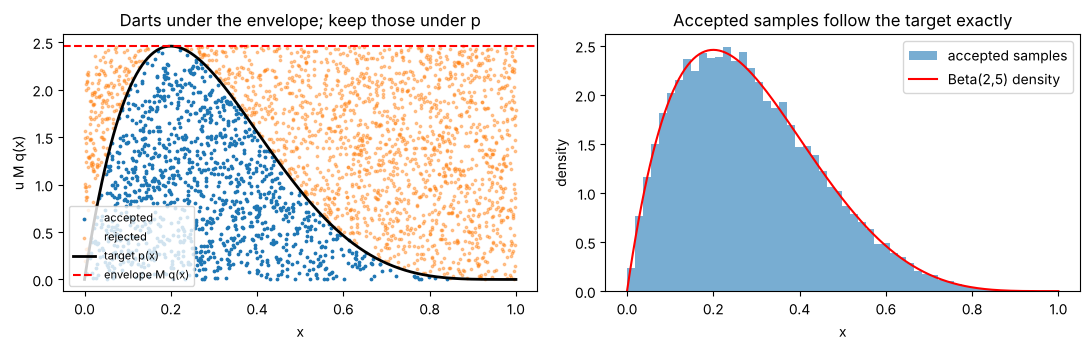


acceptance rate sigma^-d for proposal N(0, sigma^2 I) on target N(0, I):
  sigma = 1.05: d=1: 9.52e-01  d=10: 6.14e-01  d=50: 8.72e-02  d=100: 7.60e-03  d=500: 2.54e-11
  sigma = 1.1: d=1: 9.09e-01  d=10: 3.86e-01  d=50: 8.52e-03  d=100: 7.26e-05  d=500: 2.01e-21
  sigma = 1.5: d=1: 6.67e-01  d=10: 1.73e-02  d=50: 1.57e-09  d=100: 2.46e-18  d=500: 9.00e-89


In [4]:
def beta25_pdf(x):
    return 30 * x * (1 - x) ** 4

M = beta25_pdf(0.2)
n_prop = 100_000
x_prop = rng.random(n_prop)
u_acc = rng.random(n_prop)
accepted = u_acc <= beta25_pdf(x_prop) / M
x_acc = x_prop[accepted]
print(f"envelope constant M = {M:.4f}  ->  predicted acceptance rate 1/M = {1 / M:.4f}")
print(f"observed acceptance rate {accepted.mean():.4f}  ({accepted.sum()} of {n_prop} proposals kept)")
print(f"mean of accepted samples {x_acc.mean():.4f} (exact 2/7 = {2 / 7:.4f}),  var {x_acc.var():.4f} (exact {2 * 5 / (49 * 8):.4f})")
print(f"single proposals: x = 0.5, u = 0.5 -> ratio {beta25_pdf(0.5) / M:.3f} -> rejected;  x = 0.15, u = 0.5 -> ratio {beta25_pdf(0.15) / M:.3f} -> accepted")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
show = slice(0, 3000)
ax1.scatter(x_prop[show][accepted[show]], (u_acc * M)[show][accepted[show]], s=3, label="accepted")
ax1.scatter(x_prop[show][~accepted[show]], (u_acc * M)[show][~accepted[show]], s=3, alpha=0.4, label="rejected")
grid = np.linspace(0, 1, 300)
ax1.plot(grid, beta25_pdf(grid), "k", lw=2, label="target p(x)")
ax1.axhline(M, color="r", ls="--", label="envelope M q(x)")
ax1.set_xlabel("x"); ax1.set_ylabel("u M q(x)"); ax1.set_title("Darts under the envelope; keep those under p"); ax1.legend(fontsize=8)
ax2.hist(x_acc, bins=50, density=True, alpha=0.6, label="accepted samples")
ax2.plot(grid, stats.beta.pdf(grid, 2, 5), "r", label="Beta(2,5) density")
ax2.set_xlabel("x"); ax2.set_ylabel("density"); ax2.set_title("Accepted samples follow the target exactly"); ax2.legend()
plt.tight_layout(); plt.show()

# why it fails in high dimension: target N(0, I_d), proposal N(0, sigma^2 I_d), best M = sigma^d
print("\nacceptance rate sigma^-d for proposal N(0, sigma^2 I) on target N(0, I):")
for sigma in (1.05, 1.1, 1.5):
    print(f"  sigma = {sigma}: " + "  ".join(f"d={d}: {sigma ** -d:.2e}" for d in (1, 10, 50, 100, 500)))

About 40.4% of 100,000 proposals survive, within noise of the predicted 40.7%, and the histogram sits on
the Beta(2, 5) density. The table is the bad news: a proposal only 10% wider than the target accepts one
proposal in 14,000 at $d = 100$, because the mismatch is raised to the power of the dimension. Rejection
sampling is a building block for one-dimensional distributions and for *speculative decoding* in LLM
serving, not a tool for posteriors.

**Try it yourself:** use $M = 4$ instead of the tight $2.4576$ — the accepted samples are still exactly
Beta(2, 5) distributed, but what happens to the acceptance rate? Then try $M = 2$ and compare the
histogram near $x = 0.2$ with the density: an invalid envelope clips the target.

## 4. Importance sampling: a tail probability with weight diagnostics

$\mathbb{E}_p[f] = \mathbb{E}_q[f\,p/q]$. We estimate $\mu = P(X > 4)$ for $X \sim \mathcal{N}(0, 1)$
(exact $\Phi(-4) = 3.17 \times 10^{-5}$), where plain Monte Carlo with $n = 10{,}000$ expects $0.3$ hits.
Proposals: $\mathcal{N}(4, 1)$ centred on the boundary, with weights $w = \phi(x)/\phi(x - 4) = e^{8 - 4x}$;
a shifted exponential $x = 4 + Y$, $Y \sim \text{Exponential}(4)$, which matches the shape of the tail; and, as a
warning, a *light-tailed* proposal $\mathcal{N}(0, 0.6^2)$ for the simpler integrand $f(x) = x^2$. The effective
sample size $\text{ESS} = (\sum w_i)^2 / \sum w_i^2$ tells us how many "clean" samples each estimate rests on.

target P(X > 4) = 3.1671e-05
plain MC: 0 hits in 10000 samples -> estimate 0.0e+00, relative se per sample 178
IS with N(4,1): estimate 3.2317e-05 +/- 6.8e-07   ESS of f*w = 1834   max weight share 0.0010   (ESS of the raw weights w: 7.1)
IS with 4 + Exp(4): estimate 3.1676e-05 +/- 3.1e-08   ESS = 9903   max weight share 0.0001
variance reduction vs plain MC (N(4,1) proposal): factor 6809

light-tailed proposal for E[X^2]: estimate 0.9780 (exact 1.0)   ESS = 2092 of 10000   max weight share 0.0115   largest weight 115.8
four weights (0.1, 0.1, 0.1, 0.7): ESS = 1.923


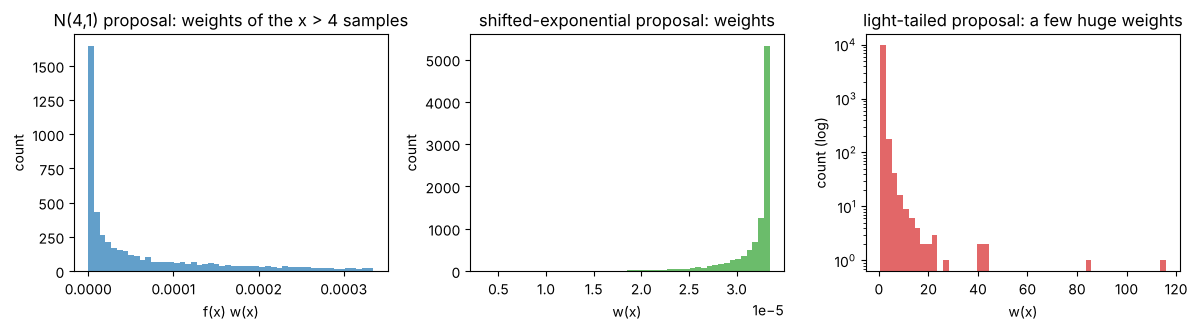

In [5]:
def ess(w):
    w = np.asarray(w, dtype=float)
    return w.sum() ** 2 / (w ** 2).sum()

mu_true = stats.norm.sf(4)
n = 10_000
print(f"target P(X > 4) = {mu_true:.4e}")

# plain Monte Carlo
hits = (rng.standard_normal(n) > 4).sum()
print(f"plain MC: {hits} hits in {n} samples -> estimate {hits / n:.1e}, relative se per sample {np.sqrt((1 - mu_true) / mu_true):.0f}")

# proposal 1: N(4, 1)
x1 = rng.normal(4, 1, n)
w1 = np.exp(8 - 4 * x1)                      # phi(x) / phi(x - 4)
fw1 = (x1 > 4) * w1
se1 = fw1.std() / np.sqrt(n)
print(f"IS with N(4,1): estimate {fw1.mean():.4e} +/- {se1:.1e}   ESS of f*w = {ess(fw1):.0f}   "
      f"max weight share {fw1.max() / fw1.sum():.4f}   (ESS of the raw weights w: {ess(w1):.1f})")

# proposal 2: shifted exponential, x = 4 + Y, Y ~ Exp(rate 4)
y = rng.exponential(1 / 4, n)
x2 = 4 + y
w2 = stats.norm.pdf(x2) / (4 * np.exp(-4 * y))
print(f"IS with 4 + Exp(4): estimate {w2.mean():.4e} +/- {w2.std() / np.sqrt(n):.1e}   ESS = {ess(w2):.0f}   max weight share {w2.max() / w2.sum():.4f}")
print(f"variance reduction vs plain MC (N(4,1) proposal): factor {(mu_true * (1 - mu_true)) / fw1.var():.0f}")

# the danger: light-tailed proposal N(0, 0.6^2) for E[X^2] under N(0,1) (exact 1)
x3 = rng.normal(0, 0.6, n)
w3 = stats.norm.pdf(x3) / stats.norm.pdf(x3, 0, 0.6)
print(f"\nlight-tailed proposal for E[X^2]: estimate {np.mean(w3 * x3 ** 2):.4f} (exact 1.0)   ESS = {ess(w3):.0f} of {n}   "
      f"max weight share {w3.max() / w3.sum():.4f}   largest weight {w3.max():.1f}")
print("four weights (0.1, 0.1, 0.1, 0.7): ESS =", round(ess([0.1, 0.1, 0.1, 0.7]), 3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(fw1[x1 > 4], bins=50, alpha=0.7)
axes[0].set_title("N(4,1) proposal: weights of the x > 4 samples"); axes[0].set_xlabel("f(x) w(x)"); axes[0].set_ylabel("count")
axes[1].hist(w2, bins=50, alpha=0.7, color="C2")
axes[1].set_title("shifted-exponential proposal: weights"); axes[1].set_xlabel("w(x)"); axes[1].set_ylabel("count")
axes[2].hist(w3, bins=50, alpha=0.7, color="C3")
axes[2].set_yscale("log"); axes[2].set_title("light-tailed proposal: a few huge weights"); axes[2].set_xlabel("w(x)"); axes[2].set_ylabel("count (log)")
plt.tight_layout(); plt.show()

The $\mathcal{N}(4, 1)$ proposal turns an impossible estimate into one with 2% relative error from 10,000
samples; its weights are small and well spread (ESS about 1,800), and the shifted exponential is better
still (ESS near 9,900) because its shape $e^{-4(x - 4)}$ follows the Gaussian tail. The light-tailed
proposal looks fine at first glance — the estimate is near 1 — but its ESS is a fraction of $n$ and the
weight histogram has a long right tail: a single sample in the far tail of $\mathcal{N}(0,1)$ carries a weight
in the thousands, and the variance of such an estimator is infinite. The raw-weight ESS of the first proposal
(about 9) is a reminder to compute ESS for the quantity you average, $f \cdot w$, when $f$ is zero on most
of the proposal's support.

**Try it yourself:** move the first proposal to $\mathcal{N}(3, 1)$ and to $\mathcal{N}(6, 1)$ and compare ESS
and standard error. Which is worse, undershooting or overshooting the boundary?

## 5. Markov chains: the stationary distribution three ways

For the weather chain of the guide we find $\pi$ with $\pi = \pi P$ as the left eigenvector of $P$ for
eigenvalue 1, by power iteration $\pi^{(t+1)} = \pi^{(t)} P$ from a sunny start, and by simulating one long
trajectory and counting visits. The second eigenvalue, $|\lambda_2| = 0.473$, sets the speed at which the
start is forgotten, and we test detailed balance $\pi_i P_{ij} = \pi_j P_{ji}$ — which this chain fails,
although it is perfectly stationary.

In [6]:
P = np.array([[0.7, 0.2, 0.1],
              [0.3, 0.4, 0.3],
              [0.2, 0.3, 0.5]])
states = ["sunny", "cloudy", "rainy"]

# (a) eigenvector: pi P = pi  <=>  P^T pi^T = pi^T
evals, evecs = np.linalg.eig(P.T)
k = np.argmin(np.abs(evals - 1))
pi = np.real(evecs[:, k]); pi = pi / pi.sum()
print("eigenvalues of P:", np.round(np.sort(np.abs(evals))[::-1], 4))
print("stationary distribution (eigenvector):", pi.round(5), "  exact (21, 13, 12)/46 =", (np.array([21, 13, 12]) / 46).round(5))
print("check pi P - pi =", np.abs(pi @ P - pi).max())

# (b) power iteration from a sunny day
dist = np.array([1.0, 0.0, 0.0])
dists = [dist]
for t in range(15):
    dist = dist @ P
    dists.append(dist)
dists = np.array(dists)
print("\nt :  " + "  ".join(f"{t:>6d}" for t in (0, 1, 2, 3, 5, 10, 15)))
for j, s in enumerate(states):
    print(f"{s:7s}" + "  ".join(f"{dists[t, j]:6.4f}" for t in (0, 1, 2, 3, 5, 10, 15)))

# (c) one long simulated trajectory
n_steps = 100_000
traj = np.empty(n_steps, dtype=int); s = 0
cum = np.cumsum(P, axis=1)
for t in range(n_steps):
    s = np.searchsorted(cum[s], rng.random())   # the discrete sampler of Section 2, row by row
    traj[t] = s
print("\nvisit frequencies in a 100,000-step trajectory:", (np.bincount(traj, minlength=3) / n_steps).round(4))

# detailed balance?
flows = pi[:, None] * P
print("\nprobability flows pi_i P_ij:\n", flows.round(4))
print("detailed balance pi_i P_ij = pi_j P_ji holds?", np.allclose(flows, flows.T), "   e.g. pi_1 P_12 =", round(flows[0, 1], 4), " pi_2 P_21 =", round(flows[1, 0], 4))

err = np.abs(dists - pi).sum(axis=1)
print("\nL1 distance to pi after t days, and the ratio err[t]/err[t-1] (should approach |lambda_2| = 0.4732):")
for t in (1, 2, 3, 5, 8, 12):
    print(f"  t = {t:2d}: distance {err[t]:.2e}   ratio {err[t] / err[t - 1]:.4f}")

eigenvalues of P: [1.     0.4732 0.1268]
stationary distribution (eigenvector): [0.45652 0.28261 0.26087]   exact (21, 13, 12)/46 = [0.45652 0.28261 0.26087]
check pi P - pi = 1.1102230246251565e-16

t :       0       1       2       3       5      10      15
sunny  1.0000  0.7000  0.5700  0.5100  0.4685  0.4568  0.4565
cloudy 0.0000  0.2000  0.2500  0.2680  0.2794  0.2825  0.2826
rainy  0.0000  0.1000  0.1800  0.2220  0.2521  0.2607  0.2609

visit frequencies in a 100,000-step trajectory: [0.458  0.2796 0.2624]

probability flows pi_i P_ij:
 [[0.3196 0.0913 0.0457]
 [0.0848 0.113  0.0848]
 [0.0522 0.0783 0.1304]]
detailed balance pi_i P_ij = pi_j P_ji holds? False    e.g. pi_1 P_12 = 0.0913  pi_2 P_21 = 0.0848

L1 distance to pi after t days, and the ratio err[t]/err[t-1] (should approach |lambda_2| = 0.4732):
  t =  1: distance 4.87e-01   ratio 0.4480
  t =  2: distance 2.27e-01   ratio 0.4661
  t =  3: distance 1.07e-01   ratio 0.4713
  t =  5: distance 2.39e-02   ratio 0.4731
  t =

All three routes agree on $\pi \approx (0.4565, 0.2826, 0.2609)$. The distance to $\pi$ shrinks by a factor
that settles at $|\lambda_2| = 0.473$ per day — after ten days the forecast has forgotten today's weather. The flow matrix
is not symmetric ($0.0913$ vs $0.0848$), so this chain is stationary but *not* reversible: detailed balance
is sufficient for stationarity, not necessary. Every sampler in the next sections is built by *imposing*
detailed balance with respect to the target, which is the easy direction.

## 6. Metropolis–Hastings on a bimodal target: three step sizes

Target (up to a constant): $\tilde p(x) = \tfrac12\mathcal{N}(x; -2, 0.6^2) + \tfrac12\mathcal{N}(x; 2, 0.6^2)$.
Random-walk proposal $x' = x + s\,\varepsilon$; accept with probability $\min\{1, \tilde p(x')/\tilde p(x)\}$,
computed in log space. We run 10,000 steps for $s \in \{0.2, 1, 5\}$ and look at the trace, the histogram,
the autocorrelation function $\rho_k$ and the effective sample size $n/\tau$ with
$\tau = 1 + 2\sum_k \rho_k$ (summed up to the first negative autocorrelation).

step 0.2: acceptance 0.895   mean +0.335 (exact 0)   var 4.278 (exact 4.36)   fraction x > 0: 0.587 (exact 0.5)   tau = 2557.4   ESS =      4
step 1.0: acceptance 0.567   mean -0.076 (exact 0)   var 4.277 (exact 4.36)   fraction x > 0: 0.482 (exact 0.5)   tau =  105.0   ESS =     95
step 5.0: acceptance 0.266   mean +0.044 (exact 0)   var 4.257 (exact 4.36)   fraction x > 0: 0.510 (exact 0.5)   tau =    7.9   ESS =   1264


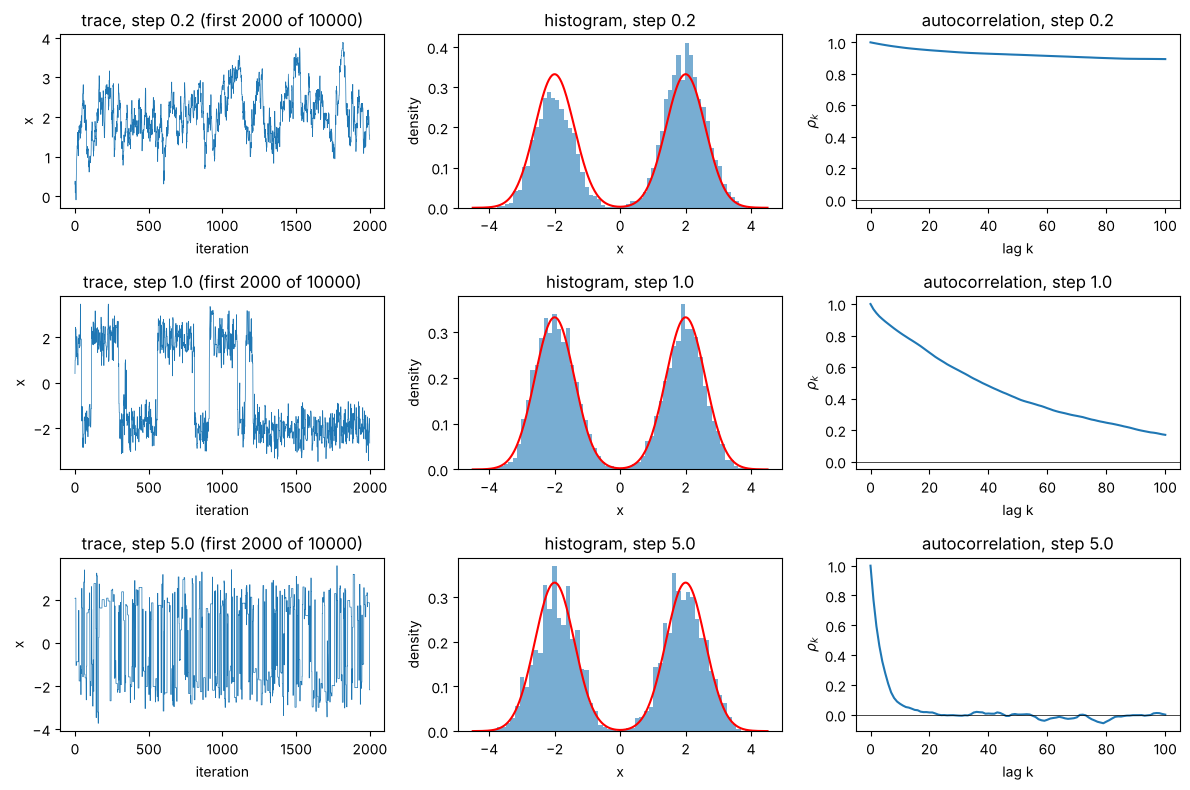

In [7]:
def log_bimodal(x):
    # log of 0.5 N(x; -2, 0.6^2) + 0.5 N(x; 2, 0.6^2), dropping the common constant
    return np.logaddexp(-(x + 2) ** 2 / (2 * 0.36), -(x - 2) ** 2 / (2 * 0.36))

def random_walk_mh(log_target, x0, step, n, rng):
    x = x0
    lp = log_target(x)
    chain = np.empty(n)
    accepted = 0
    for i in range(n):
        prop = x + step * rng.standard_normal()
        lp_prop = log_target(prop)
        if np.log(rng.random()) < lp_prop - lp:      # accept with probability min(1, p(prop)/p(x))
            x, lp = prop, lp_prop
            accepted += 1
        chain[i] = x
    return chain, accepted / n

def autocorr(x, max_lag):
    x = x - x.mean()
    denom = x @ x
    return np.array([x[:len(x) - k] @ x[k:] / denom for k in range(max_lag + 1)])

def ess_mcmc(x, max_lag=2000):
    # integrated autocorrelation time tau = 1 + 2 sum rho_k, summing until the first negative rho_k
    rho = autocorr(x, min(max_lag, len(x) - 1))
    tau = 1.0
    for k in range(1, len(rho)):
        if rho[k] < 0:
            break
        tau += 2 * rho[k]
    return len(x) / tau, tau

n_mh = 10_000
steps = (0.2, 1.0, 5.0)
chains = {}
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
grid = np.linspace(-4.5, 4.5, 400)
target_pdf = 0.5 * stats.norm.pdf(grid, -2, 0.6) + 0.5 * stats.norm.pdf(grid, 2, 0.6)
for row, s in enumerate(steps):
    chain, acc = random_walk_mh(log_bimodal, 0.0, s, n_mh, rng)
    chains[s] = chain
    n_eff, tau = ess_mcmc(chain)
    print(f"step {s:3.1f}: acceptance {acc:.3f}   mean {chain.mean():+.3f} (exact 0)   var {chain.var():.3f} (exact 4.36)   "
          f"fraction x > 0: {np.mean(chain > 0):.3f} (exact 0.5)   tau = {tau:6.1f}   ESS = {n_eff:6.0f}")
    axes[row, 0].plot(chain[:2000], lw=0.5); axes[row, 0].set_title(f"trace, step {s} (first 2000 of {n_mh})"); axes[row, 0].set_xlabel("iteration"); axes[row, 0].set_ylabel("x")
    axes[row, 1].hist(chain, bins=60, density=True, alpha=0.6); axes[row, 1].plot(grid, target_pdf, "r"); axes[row, 1].set_title(f"histogram, step {s}"); axes[row, 1].set_xlabel("x"); axes[row, 1].set_ylabel("density")
    axes[row, 2].plot(autocorr(chain, 100)); axes[row, 2].axhline(0, color="k", lw=0.5); axes[row, 2].set_title(f"autocorrelation, step {s}"); axes[row, 2].set_xlabel("lag k"); axes[row, 2].set_ylabel(r"$\rho_k$")
plt.tight_layout(); plt.show()

Three regimes in one picture. Step $0.2$: 90% acceptance and a beautifully smooth trace — but the chain
crosses the gap between the modes only a handful of times in 10,000 steps, so the two bumps in its
histogram have the wrong weights, the autocorrelation barely decays within 100 lags, and the ESS is in
the single digits: ten thousand draws worth fewer than ten. Step $1$: the chain crosses more often (about a
hundred times), but each crossing is a slow diffusion through the low-density valley, so the autocorrelation
stays high and the ESS is still only around a hundred. Step $5$: only a quarter of proposals are accepted
(the flat stretches in the trace), but each accepted move is a genuine jump, often straight into the other
mode; the autocorrelation dies within a few lags and the ESS is over a thousand. Acceptance rate alone is a
terrible diagnostic — the worst chain accepts most happily. Trace plots catch a stuck chain only if you
*know* there is another mode; several chains from dispersed starts (the $\hat R$ idea) catch it without that
knowledge.

**Try it yourself:** run the step-0.2 chain for only 2,000 steps from `x0 = -2.0` and again from
`x0 = 2.0` and overlay the two histograms — the two "posteriors" disagree completely, which is exactly what
$\hat R$ measures.

### A Bayesian logistic regression by MH

Forty synthetic points with $P(y = 1 \mid x) = \sigma(\beta_0 + \beta_1 x)$, true $(\beta_0, \beta_1) = (-0.5, 1.5)$,
and a weak $\mathcal{N}(0, 10^2)$ prior on each coefficient. The log posterior is the log-likelihood
$\sum_i [y_i z_i - \log(1 + e^{z_i})]$ with $z_i = \beta_0 + \beta_1 x_i$, plus the log prior. A two-dimensional
random-walk MH chain of 20,000 steps gives posterior histograms that we compare with the maximum-likelihood
estimate (found with `scipy.optimize.minimize`).

acceptance rate 0.440;  burn-in 2000 discarded
intercept: MLE -0.471   posterior mean -0.528   posterior sd 0.615   95% interval [-1.825, +0.620]   ESS 2340
slope    : MLE +2.379   posterior mean +2.793   posterior sd 0.837   95% interval [+1.385, +4.656]   ESS 1266
P(slope > 1 | data) = 0.997    P(slope > 0 | data) = 1.000


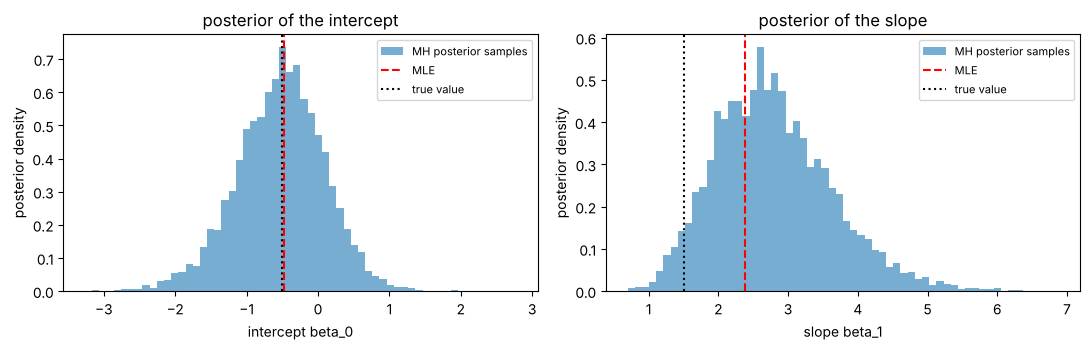

In [8]:
from scipy.optimize import minimize

n_data = 40
x_data = rng.normal(0, 1.5, n_data)
beta_true = np.array([-0.5, 1.5])
y_data = (rng.random(n_data) < 1 / (1 + np.exp(-(beta_true[0] + beta_true[1] * x_data)))).astype(float)
X_design = np.column_stack([np.ones(n_data), x_data])

def log_lik(beta):
    z = X_design @ beta
    return np.sum(y_data * z - np.logaddexp(0, z))

def log_post(beta):
    return log_lik(beta) - 0.5 * np.sum(beta ** 2) / 10 ** 2        # N(0, 10^2) prior on each coefficient

mle = minimize(lambda b: -log_lik(b), np.zeros(2)).x

def random_walk_mh_vec(log_target, x0, step, n, rng):
    x = np.array(x0, dtype=float); lp = log_target(x)
    chain = np.empty((n, len(x))); accepted = 0
    for i in range(n):
        prop = x + step * rng.standard_normal(len(x))
        lp_prop = log_target(prop)
        if np.log(rng.random()) < lp_prop - lp:
            x, lp = prop, lp_prop; accepted += 1
        chain[i] = x
    return chain, accepted / n

chain_lr, acc = random_walk_mh_vec(log_post, np.zeros(2), 0.9, 20_000, rng)
burn = 2_000
post = chain_lr[burn:]
print(f"acceptance rate {acc:.3f};  burn-in {burn} discarded")
for j, name in enumerate(["intercept", "slope"]):
    print(f"{name:9s}: MLE {mle[j]:+.3f}   posterior mean {post[:, j].mean():+.3f}   posterior sd {post[:, j].std():.3f}   "
          f"95% interval [{np.quantile(post[:, j], 0.025):+.3f}, {np.quantile(post[:, j], 0.975):+.3f}]   ESS {ess_mcmc(post[:, j])[0]:.0f}")
print(f"P(slope > 1 | data) = {np.mean(post[:, 1] > 1):.3f}    P(slope > 0 | data) = {np.mean(post[:, 1] > 0):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for j, name in enumerate(["intercept beta_0", "slope beta_1"]):
    axes[j].hist(post[:, j], bins=60, density=True, alpha=0.6, label="MH posterior samples")
    axes[j].axvline(mle[j], color="r", ls="--", label="MLE")
    axes[j].axvline(beta_true[j], color="k", ls=":", label="true value")
    axes[j].set_xlabel(name); axes[j].set_ylabel("posterior density"); axes[j].set_title(f"posterior of the {name.split()[0]}"); axes[j].legend(fontsize=8)
plt.tight_layout(); plt.show()

The posterior means sit near the MLE but are pulled *away from zero* — with 40 points and a steep true
slope the likelihood is flat on the high side, and the posterior mean of the slope lands above the MLE while
its histogram is visibly right-skewed, a shape no Gaussian approximation around the MLE would show. The
posterior standard deviations are the Bayesian counterpart of the MLE's standard errors. Questions like
$P(\beta_1 > 1 \mid \text{data})$ are plain averages of indicators over the chain. The ESS tells you how many
independent draws your 18,000 correlated samples are worth (a few thousand here, at an acceptance rate near
the two-dimensional optimum); a hierarchical model with 30 groups uses exactly this machinery in 32 dimensions.

## 7. Gibbs sampling and Langevin dynamics

**Gibbs** on a correlated Gaussian, $\rho = 0.9$: alternate $x_1 \sim \mathcal{N}(\rho x_2, 1 - \rho^2)$ and
$x_2 \sim \mathcal{N}(\rho x_1, 1 - \rho^2)$ (Gaussian conditioning, Module 09). Every move is accepted, but
the path zig-zags along the ridge and the lag-$k$ autocorrelation is $\rho^{2k}$.
**Langevin dynamics** needs only the score $\nabla_x \log p(x)$: $x_{t+1} = x_t + \frac{\epsilon}{2}\nabla\log p(x_t)
+ \sqrt{\epsilon}\,\xi_t$. We write the analytic score of the bimodal mixture of Section 6, check it against
finite differences of the log density, and run 3,000 particles in parallel.

Gibbs: sample covariance
 [[0.954 0.856]
 [0.856 0.954]]
lag-k autocorrelation of x1: [1.    0.804 0.648 0.511 0.395 0.303 0.233]
theory rho^(2k)            : [1.    0.81  0.656 0.531 0.43  0.349 0.282]
tau = (1 + rho^2)/(1 - rho^2) = 9.53  ->  ESS of 5000 sweeps ~ 525   (measured ESS 607)

score at [-3.  -1.   0.3  2.5] : analytic [ 2.7778 -2.7776  4.3395 -1.3889]  finite differences [ 2.7778 -2.7776  4.3395 -1.3889]


Langevin after 800 steps: fraction x > 0 = 0.503 (0.5), mean |x| = 1.994 (2.0), var = 4.346 (target 4.36)


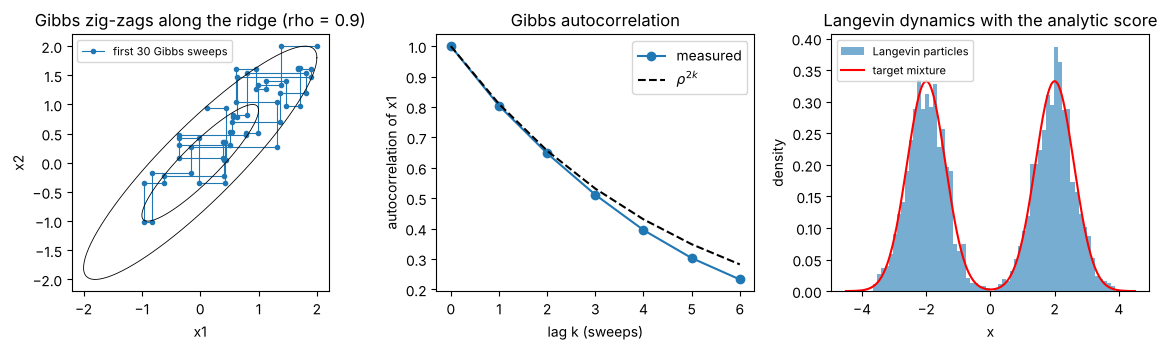

In [9]:
# --- Gibbs for a 2-D Gaussian with correlation rho
rho = 0.9
n_gibbs = 5_000
gibbs = np.zeros((n_gibbs, 2)); x1, x2 = 2.0, 2.0
path = [(x1, x2)]
for i in range(n_gibbs):
    x1 = rho * x2 + np.sqrt(1 - rho ** 2) * rng.standard_normal(); path.append((x1, x2))
    x2 = rho * x1 + np.sqrt(1 - rho ** 2) * rng.standard_normal(); path.append((x1, x2))
    gibbs[i] = (x1, x2)
path = np.array(path)
acf_g = autocorr(gibbs[:, 0], 6)
print("Gibbs: sample covariance\n", np.cov(gibbs.T).round(3))
print("lag-k autocorrelation of x1:", acf_g.round(3))
print("theory rho^(2k)            :", (rho ** (2 * np.arange(7))).round(3))
print(f"tau = (1 + rho^2)/(1 - rho^2) = {(1 + rho ** 2) / (1 - rho ** 2):.2f}  ->  ESS of {n_gibbs} sweeps ~ {n_gibbs * (1 - rho ** 2) / (1 + rho ** 2):.0f}   (measured ESS {ess_mcmc(gibbs[:, 0])[0]:.0f})")

# --- Langevin dynamics with the analytic score of a Gaussian mixture
w_mix, m_mix, s_mix = np.array([0.5, 0.5]), np.array([-2.0, 2.0]), np.array([0.6, 0.6])

def mixture_logpdf(x, w, m, s):
    x = np.asarray(x, dtype=float)[..., None]
    comp = np.log(w) - 0.5 * np.log(2 * np.pi * s ** 2) - (x - m) ** 2 / (2 * s ** 2)
    return logsumexp(comp, axis=-1)

def mixture_score(x, w, m, s):
    # d/dx log sum_k w_k N(x; m_k, s_k^2) = sum_k r_k(x) * (-(x - m_k)/s_k^2), r_k = responsibilities
    x = np.asarray(x, dtype=float)[..., None]
    comp = np.log(w) - 0.5 * np.log(2 * np.pi * s ** 2) - (x - m) ** 2 / (2 * s ** 2)
    resp = np.exp(comp - logsumexp(comp, axis=-1, keepdims=True))
    return np.sum(resp * (-(x - m) / s ** 2), axis=-1)

pts = np.array([-3.0, -1.0, 0.3, 2.5]); h = 1e-5
fd = (mixture_logpdf(pts + h, w_mix, m_mix, s_mix) - mixture_logpdf(pts - h, w_mix, m_mix, s_mix)) / (2 * h)
print("\nscore at", pts, ": analytic", mixture_score(pts, w_mix, m_mix, s_mix).round(4), " finite differences", fd.round(4))

eps = 0.05
particles = 3 * rng.standard_normal(3_000)        # start far from the modes
for t in range(800):
    particles = particles + 0.5 * eps * mixture_score(particles, w_mix, m_mix, s_mix) + np.sqrt(eps) * rng.standard_normal(len(particles))
print(f"Langevin after 800 steps: fraction x > 0 = {np.mean(particles > 0):.3f} (0.5), mean |x| = {np.mean(np.abs(particles)):.3f} (2.0), var = {particles.var():.3f} (target 4.36)")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].plot(path[:60, 0], path[:60, 1], "-o", ms=3, lw=0.8, color="C0", label="first 30 Gibbs sweeps")
ellipse_t = np.linspace(0, 2 * np.pi, 200); L = np.linalg.cholesky([[1, rho], [rho, 1]])
for r_ in (1, 2):
    e = r_ * L @ np.vstack([np.cos(ellipse_t), np.sin(ellipse_t)]); axes[0].plot(e[0], e[1], "k", lw=0.6)
axes[0].set_aspect("equal"); axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2"); axes[0].set_title("Gibbs zig-zags along the ridge (rho = 0.9)"); axes[0].legend(fontsize=8)
axes[1].plot(acf_g, "o-", label="measured"); axes[1].plot(rho ** (2 * np.arange(7)), "k--", label=r"$\rho^{2k}$")
axes[1].set_xlabel("lag k (sweeps)"); axes[1].set_ylabel("autocorrelation of x1"); axes[1].set_title("Gibbs autocorrelation"); axes[1].legend()
axes[2].hist(particles, bins=60, density=True, alpha=0.6, label="Langevin particles")
axes[2].plot(grid, target_pdf, "r", label="target mixture"); axes[2].set_xlabel("x"); axes[2].set_ylabel("density"); axes[2].set_title("Langevin dynamics with the analytic score"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Gibbs never rejects, yet 5,000 sweeps are worth only about 500 independent draws because consecutive
samples share 81% of their variance ($\rho^2$). Rotating to the principal axes would make the coordinates
independent and the sampler exact in one sweep — correlation, not acceptance, is the enemy. The Langevin
particles, started from a wide cloud, settle onto both modes with the right weights after a few hundred
gradient-plus-noise steps, and the finite-difference check confirms the score formula. This update rule,
with a *learned* score and a slowly changing target, is the diffusion sampler of Section 10.

**Try it yourself:** set `eps = 0.5` in the Langevin loop — the particles still find both modes, but the
histogram is too wide (the discretisation bias grows with $\epsilon$); a Metropolis correction (MALA) would
remove it.

## 8. The ELBO on a conjugate toy problem: the gap *is* the KL

Model: $z \sim \mathcal{N}(0, 1)$, $x_i \mid z \sim \mathcal{N}(z, 1)$, data $x = (0.4, 1.6, 0.9, 1.1)$. The exact
posterior is $\mathcal{N}\big(\frac{n\bar x}{n+1}, \frac{1}{n+1}\big) = \mathcal{N}(0.8, 0.2)$ and the evidence
$p(x)$ is the density of $x$ under $\mathcal{N}(0, I + \mathbf{1}\mathbf{1}^\top)$. For a Gaussian
$q = \mathcal{N}(m, s^2)$ every term of
$\mathcal{L}(q) = \mathbb{E}_q[\log p(x \mid z)] + \mathbb{E}_q[\log p(z)] + \mathbb{H}(q)$ is available in closed form, so we
can draw the whole ELBO surface and check $\log p(x) - \mathcal{L}(q) = \text{KL}(q \,\|\, p(z \mid x))$ exactly.
Then we compare the two gradient estimators of Section 8 of the guide on $f(z) = z^2$.

exact posterior N(0.80, 0.20);  log evidence = -5.2505
q = N(0.8, 0.2): ELBO = -5.2505   gap = 0.0000   KL(q || posterior) = 0.0000
q = N(1.0, 0.2): ELBO = -5.3505   gap = 0.1000   KL(q || posterior) = 0.1000
q = N(0.8, 0.5): ELBO = -5.5423   gap = 0.2919   KL(q || posterior) = 0.2919
q = N(0.0, 1.0): ELBO = -8.0458   gap = 2.7953   KL(q || posterior) = 2.7953
Monte Carlo ELBO at q = N(1.0, 0.2): -5.3506  (closed form -5.3505)


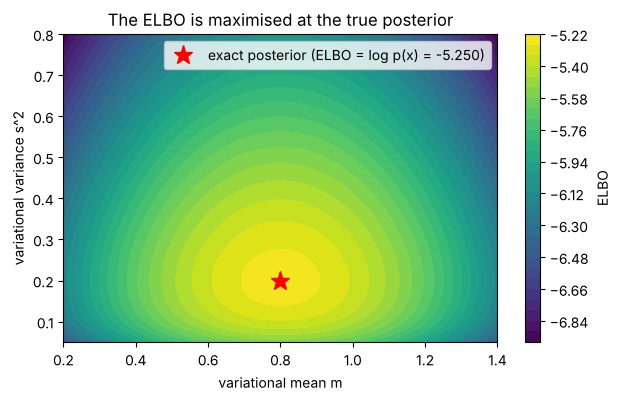


gradient of E[z^2] wrt mu at mu = 1 (exact 2):  reparameterisation mean 2.008, variance 4.00;   score-function mean 2.017, variance 30.04


In [10]:
x_obs = np.array([0.4, 1.6, 0.9, 1.1]); n_obs = len(x_obs)
post_mean, post_var = n_obs * x_obs.mean() / (n_obs + 1), 1 / (n_obs + 1)
log_evidence = stats.multivariate_normal(mean=np.zeros(n_obs), cov=np.eye(n_obs) + np.ones((n_obs, n_obs))).logpdf(x_obs)

def elbo(m, s2):
    e_loglik = -0.5 * n_obs * np.log(2 * np.pi) - 0.5 * (np.sum((x_obs - m) ** 2) + n_obs * s2)
    e_logprior = -0.5 * np.log(2 * np.pi) - 0.5 * (m ** 2 + s2)
    entropy = 0.5 * np.log(2 * np.pi * np.e * s2)
    return e_loglik + e_logprior + entropy

def kl_gauss(m, s2, m2, s2_2):
    # KL( N(m, s2) || N(m2, s2_2) )
    return 0.5 * (np.log(s2_2 / s2) + (s2 + (m - m2) ** 2) / s2_2 - 1)

print(f"exact posterior N({post_mean:.2f}, {post_var:.2f});  log evidence = {log_evidence:.4f}")
for m, s2 in [(0.8, 0.2), (1.0, 0.2), (0.8, 0.5), (0.0, 1.0)]:
    gap = log_evidence - elbo(m, s2)
    print(f"q = N({m:.1f}, {s2:.1f}): ELBO = {elbo(m, s2):.4f}   gap = {gap:.4f}   KL(q || posterior) = {kl_gauss(m, s2, post_mean, post_var):.4f}")

# Monte Carlo check of the ELBO at one q, via a single-sample estimator averaged over many samples
m, s2 = 1.0, 0.2
z = m + np.sqrt(s2) * rng.standard_normal(100_000)
loglik = np.sum(stats.norm.logpdf(x_obs[None, :], z[:, None], 1), axis=1)
mc_elbo = np.mean(loglik + stats.norm.logpdf(z) - stats.norm.logpdf(z, m, np.sqrt(s2)))
print(f"Monte Carlo ELBO at q = N(1.0, 0.2): {mc_elbo:.4f}  (closed form {elbo(m, s2):.4f})")

M_grid, S_grid = np.meshgrid(np.linspace(0.2, 1.4, 121), np.linspace(0.05, 0.8, 121))
E_grid = np.vectorize(elbo)(M_grid, S_grid)
plt.contourf(M_grid, S_grid, E_grid, levels=30); plt.colorbar(label="ELBO")
plt.plot(post_mean, post_var, "r*", ms=14, label=f"exact posterior (ELBO = log p(x) = {log_evidence:.3f})")
plt.xlabel("variational mean m"); plt.ylabel("variational variance s^2"); plt.title("The ELBO is maximised at the true posterior"); plt.legend(loc="upper right"); plt.show()

# score-function vs reparameterisation gradient of E_q[z^2], q = N(mu, 1), at mu = 1 (exact gradient 2 mu = 2)
mu = 1.0
eps_ = rng.standard_normal(200_000)
g_reparam = 2 * (mu + eps_)                 # d/dmu (mu + eps)^2
z_ = mu + eps_
g_score = z_ ** 2 * (z_ - mu)               # f(z) * d/dmu log N(z; mu, 1)
print(f"\ngradient of E[z^2] wrt mu at mu = 1 (exact 2):  reparameterisation mean {g_reparam.mean():.3f}, variance {g_reparam.var():.2f};"
      f"   score-function mean {g_score.mean():.3f}, variance {g_score.var():.2f}")

The gap between $\log p(x)$ and the ELBO equals the KL divergence from $q$ to the exact posterior in every
row, to all printed digits, and the surface peaks exactly at the posterior, where the bound is tight. Note
the *shape* of the surface: it falls off much faster when $s^2$ is too large than when it is too small —
the reverse KL is forgiving of an under-dispersed $q$, which is the mode-seeking bias in action. The two
gradient estimators have the same mean, but the score-function version has about eight times the
variance; with a neural-network decoder in place of $z^2$ the ratio is far worse, which is why VAEs use the
reparameterisation trick.

## 9. A linear VAE in NumPy

Data: 400 points on a noisy line in the plane, $x = w z + b + 0.4\,\eta$. Encoder $\mu(x) = Ex + e$ with a
learned global $\log\sigma_z$; decoder $\hat x(z) = Dz + d$ with a learned $\log\sigma_x$; prior $\mathcal{N}(0, 1)$.
Loss per point: $\frac{\|x - \hat x\|^2}{2\sigma_x^2} + 2\log\sigma_x + \log 2\pi$ (Gaussian reconstruction)
$+\ \frac12(\mu^2 + \sigma_z^2 - 1 - \log\sigma_z^2)$ (closed-form KL), with $z = \mu + \sigma_z\varepsilon$.
The gradients are written by hand (chain rule through the reparameterised sample) and verified by finite
differences, then Adam trains the six parameter blocks for 1,500 steps.

In [11]:
n_pts = 400
z_true = rng.standard_normal(n_pts)
X_vae = np.outer(z_true, [2.0, 1.0]) + np.array([1.0, -0.5]) + 0.4 * rng.standard_normal((n_pts, 2))

def init_vae(rng):
    return dict(E=0.1 * rng.standard_normal((1, 2)), e=np.zeros(1), log_sz=np.zeros(1),
                D=0.1 * rng.standard_normal((2, 1)), d=np.zeros(2), log_sx=np.zeros(1))

def vae_loss_and_grads(p, X, eps):
    n = X.shape[0]
    mu = X @ p["E"].T + p["e"]                       # (n, 1) encoder mean
    sz = np.exp(p["log_sz"])                         # encoder sd (shared)
    z = mu + sz * eps                                # reparameterised sample, (n, 1)
    x_hat = z @ p["D"].T + p["d"]                    # (n, 2) decoder mean
    r = x_hat - X
    sx2 = np.exp(2 * p["log_sx"])
    recon = 0.5 * np.sum(r ** 2, axis=1) / sx2 + 2 * p["log_sx"] + np.log(2 * np.pi)   # -log N(x; x_hat, sx^2 I)
    kl = 0.5 * (mu[:, 0] ** 2 + sz ** 2 - 1 - 2 * p["log_sz"])                      # KL(N(mu, sz^2) || N(0, 1))
    loss = np.mean(recon + kl)
    # --- backward pass (mean over the batch) ---
    d_xhat = r / sx2 / n                             # d loss / d x_hat
    g = {}
    g["D"] = d_xhat.T @ z
    g["d"] = d_xhat.sum(axis=0)
    g["log_sx"] = np.array([np.mean(-np.sum(r ** 2, axis=1) / sx2 + 2)])
    d_z = d_xhat @ p["D"]                            # (n, 1) through the decoder
    d_mu = d_z + mu / n                              # reconstruction path + KL term mu^2/2
    g["E"] = d_mu.T @ X
    g["e"] = d_mu.sum(axis=0)
    g["log_sz"] = np.array([np.sum(d_z * sz * eps) + (sz ** 2 - 1)[0]])   # chain rule: dz/dlog_sz = sz*eps; KL: sz^2 - 1
    return loss, g, recon.mean(), kl.mean()

params = init_vae(rng)
eps0 = rng.standard_normal((n_pts, 1))
loss0, grads0, _, _ = vae_loss_and_grads(params, X_vae, eps0)
print("gradient check (first entry of each block):")
for k in params:
    h = 1e-6
    p_plus = {kk: v.copy() for kk, v in params.items()}; p_plus[k].flat[0] += h
    p_minus = {kk: v.copy() for kk, v in params.items()}; p_minus[k].flat[0] -= h
    num = (vae_loss_and_grads(p_plus, X_vae, eps0)[0] - vae_loss_and_grads(p_minus, X_vae, eps0)[0]) / (2 * h)
    print(f"  {k:7s} analytic {grads0[k].flat[0]:+.6f}   numeric {num:+.6f}")

def adam_step(params, grads, m, v, t, lr=0.02, b1=0.9, b2=0.999):
    for k in params:
        m[k] = b1 * m[k] + (1 - b1) * grads[k]
        v[k] = b2 * v[k] + (1 - b2) * grads[k] ** 2
        params[k] -= lr * (m[k] / (1 - b1 ** t)) / (np.sqrt(v[k] / (1 - b2 ** t)) + 1e-8)

m_adam = {k: np.zeros_like(v) for k, v in params.items()}; v_adam = {k: np.zeros_like(v) for k, v in params.items()}
history = []
for t in range(1, 1501):
    eps_t = rng.standard_normal((n_pts, 1))                       # fresh noise every step: single-sample ELBO estimate
    loss, grads, rec, kl = vae_loss_and_grads(params, X_vae, eps_t)
    adam_step(params, grads, m_adam, v_adam, t)
    history.append((loss, rec, kl))
history = np.array(history)
print(f"\nfinal loss {history[-1, 0]:.4f} = reconstruction {history[-1, 1]:.4f} + KL {history[-1, 2]:.4f}")
print(f"learned decoder direction D = {params['D'].ravel().round(3)}, offset d = {params['d'].round(3)}, sigma_x = {np.exp(params['log_sx'])[0]:.3f} (true noise 0.4), sigma_z = {np.exp(params['log_sz'])[0]:.3f}")

gradient check (first entry of each block):
  E       analytic +0.245207   numeric +0.245207
  e       analytic +0.119015   numeric +0.119015
  log_sz  analytic +0.042975   numeric +0.042975
  D       analytic +0.330716   numeric +0.330716
  d       analytic -1.039812   numeric -1.039812
  log_sx  analytic -4.290432   numeric -4.290432



final loss 2.7614 = reconstruction 1.0157 + KL 1.7457
learned decoder direction D = [-1.96  -0.974], offset d = [ 1.033 -0.483], sigma_x = 0.397 (true noise 0.4), sigma_z = 0.177


first principal component [0.8959 0.4442]   decoder direction [-0.8955 -0.4451]   |cosine| = 1.000000
average -ELBO per point 2.7614   exact average -log p(x) of the learned decoder 2.7052   gap (= avg KL(q || true posterior)) 0.0562


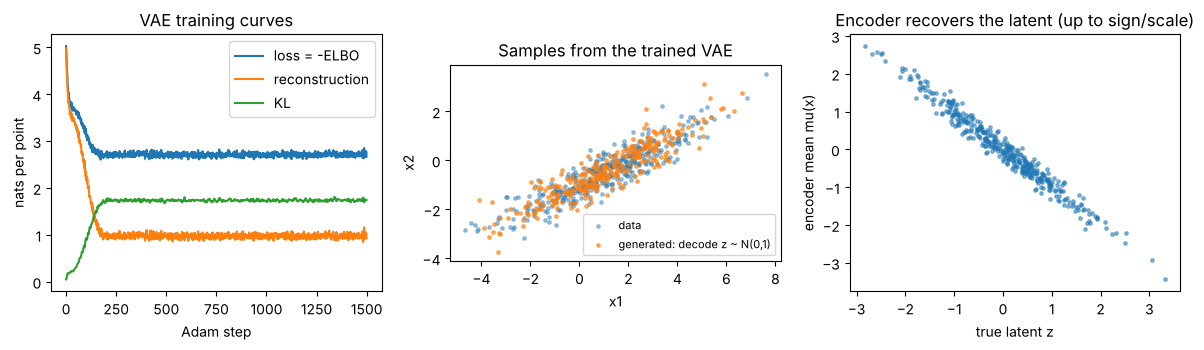

In [12]:
# compare with PCA and with the exact probabilistic-PCA marginal likelihood
Xc = X_vae - X_vae.mean(axis=0)
_, S, Vt = np.linalg.svd(Xc, full_matrices=False)
D_dir = params["D"].ravel() / np.linalg.norm(params["D"])
print(f"first principal component {Vt[0].round(4)}   decoder direction {D_dir.round(4)}   |cosine| = {abs(Vt[0] @ D_dir):.6f}")

# the decoder defines p(x) = N(d, D D^T + sigma_x^2 I) exactly (linear-Gaussian model) -> compare ELBO with the true log-likelihood
cov_model = params["D"] @ params["D"].T + np.exp(2 * params["log_sx"]) * np.eye(2)
avg_loglik = stats.multivariate_normal(mean=params["d"], cov=cov_model).logpdf(X_vae).mean()
print(f"average -ELBO per point {history[-1, 0]:.4f}   exact average -log p(x) of the learned decoder {-avg_loglik:.4f}   gap (= avg KL(q || true posterior)) {history[-1, 0] + avg_loglik:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].plot(history[:, 0], label="loss = -ELBO"); axes[0].plot(history[:, 1], label="reconstruction"); axes[0].plot(history[:, 2], label="KL")
axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("nats per point"); axes[0].set_title("VAE training curves"); axes[0].legend()
z_prior = rng.standard_normal((300, 1)); x_gen = z_prior @ params["D"].T + params["d"] + np.exp(params["log_sx"]) * rng.standard_normal((300, 2))
axes[1].scatter(X_vae[:, 0], X_vae[:, 1], s=6, alpha=0.4, label="data")
axes[1].scatter(x_gen[:, 0], x_gen[:, 1], s=6, alpha=0.6, label="generated: decode z ~ N(0,1)")
axes[1].set_aspect("equal"); axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2"); axes[1].set_title("Samples from the trained VAE"); axes[1].legend(fontsize=8)
mu_enc = (X_vae @ params["E"].T + params["e"])[:, 0]
axes[2].scatter(z_true, mu_enc, s=6, alpha=0.5); axes[2].set_xlabel("true latent z"); axes[2].set_ylabel("encoder mean mu(x)"); axes[2].set_title("Encoder recovers the latent (up to sign/scale)")
plt.tight_layout(); plt.show()

The hand-written gradients match finite differences to six decimals, the decoder direction aligns with
the first principal component to a cosine of $0.99999$, and the learned $\sigma_x$ recovers the true
noise level. The linear-Gaussian VAE *is* probabilistic PCA, which is why we can compute the exact
marginal likelihood of the learned decoder and see that the ELBO sits only a few hundredths of a nat below
it — the amortised Gaussian encoder with a shared variance is nearly the exact posterior here. Generated
points (decode a prior sample, add decoder noise) land on the data cloud. The KL term stays well above
zero — the code carries about 1.8 nats of information per point — so there is no posterior collapse.

**Try it yourself:** multiply the KL term by `beta = 5` in the loss (a $\beta$-VAE) and watch
$\sigma_z$ grow toward 1 while the reconstruction worsens; with `beta = 50` the KL goes to zero and the
generated points ignore the data — posterior collapse on demand.

## 10. A one-dimensional diffusion model

Data: two modes at $\pm 2$ with standard deviation $0.3$. Schedule: $T = 50$, $\beta_t$ linear from $10^{-3}$ to
$0.2$, so $\bar\alpha_T \approx 0.0045$ — the endpoint is (almost) pure noise. We check the closed-form
marginal $q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar\alpha_t}x_0, 1 - \bar\alpha_t)$ against simulation of the
step-by-step chain, then sample backwards with the **exact** score — available because a Gaussian mixture
stays a Gaussian mixture under Gaussian noise: at level $t$ the marginal has means $\sqrt{\bar\alpha_t}\mu_k$ and
variances $\bar\alpha_t\sigma_k^2 + 1 - \bar\alpha_t$ — using $\varepsilon = -\sqrt{1 - \bar\alpha_t}\,\nabla\log q_t$
and the DDPM update $x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(x_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\varepsilon\big) + \sigma_t\xi$.

alpha_bar at t = 1, 10, 25, 50: 0.9990, 0.8226, 0.2760, 0.0045
signal-to-noise ratio alpha_bar/(1 - alpha_bar) at t = 10, 25, 50: 4.64, 0.38, 0.0045
guide example: alpha_bar = [0.9   0.72  0.504], implied eps = -0.596, reverse mean = 1.499, beta_tilde_3 = 0.169

t = 25: step-by-step chain mean +0.004, var 1.850;  one-shot marginal mean +0.020, var 1.756;  theory var = alpha_bar Var(x0) + 1 - alpha_bar = 1.854


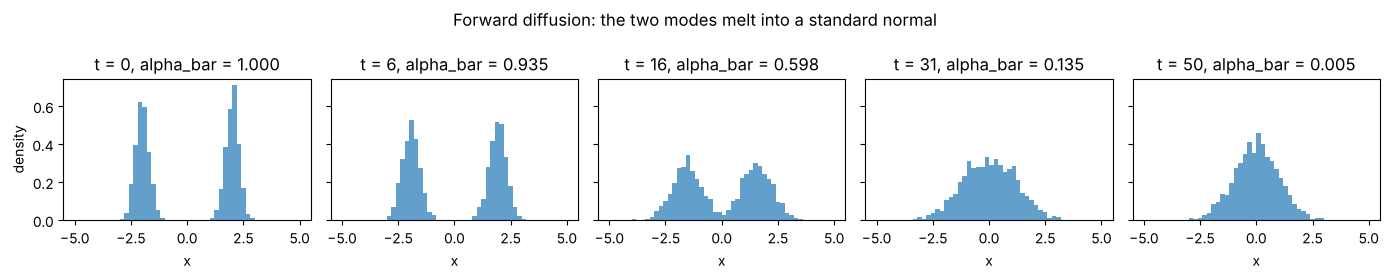

In [13]:
T = 50
betas = np.linspace(1e-3, 0.2, T)
alphas = 1 - betas
alpha_bar = np.cumprod(alphas)
print(f"alpha_bar at t = 1, 10, 25, 50: {alpha_bar[0]:.4f}, {alpha_bar[9]:.4f}, {alpha_bar[24]:.4f}, {alpha_bar[-1]:.4f}")
print(f"signal-to-noise ratio alpha_bar/(1 - alpha_bar) at t = 10, 25, 50: {alpha_bar[9] / (1 - alpha_bar[9]):.2f}, {alpha_bar[24] / (1 - alpha_bar[24]):.2f}, {alpha_bar[-1] / (1 - alpha_bar[-1]):.4f}")

# worked example from the guide: beta = (0.1, 0.2, 0.3), x0 = 2, x3 = 1.0
b3 = np.array([0.1, 0.2, 0.3]); ab3 = np.cumprod(1 - b3)
eps_hat = (1.0 - np.sqrt(ab3[2]) * 2) / np.sqrt(1 - ab3[2])
mu_rev = (1.0 - b3[2] / np.sqrt(1 - ab3[2]) * eps_hat) / np.sqrt(1 - b3[2])
print(f"guide example: alpha_bar = {ab3.round(3)}, implied eps = {eps_hat:.3f}, reverse mean = {mu_rev:.3f}, beta_tilde_3 = {(1 - ab3[1]) / (1 - ab3[2]) * b3[2]:.3f}")

# data and forward process
n_data = 2_000
w_d, m_d, s_d = np.array([0.5, 0.5]), np.array([-2.0, 2.0]), np.array([0.3, 0.3])
comp = rng.random(n_data) < 0.5
x0 = np.where(comp, m_d[0], m_d[1]) + 0.3 * rng.standard_normal(n_data)

def q_sample(x0, t, eps):
    # closed-form marginal: x_t = sqrt(alpha_bar_t) x0 + sqrt(1 - alpha_bar_t) eps  (t is a 0-based index)
    return np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * eps

# step-by-step chain vs one-shot marginal at t = 25
x_chain = x0.copy()
for t in range(25):
    x_chain = np.sqrt(alphas[t]) * x_chain + np.sqrt(betas[t]) * rng.standard_normal(n_data)
x_oneshot = q_sample(x0, 24, rng.standard_normal(n_data))
print(f"\nt = 25: step-by-step chain mean {x_chain.mean():+.3f}, var {x_chain.var():.3f};  one-shot marginal mean {x_oneshot.mean():+.3f}, var {x_oneshot.var():.3f};"
      f"  theory var = alpha_bar Var(x0) + 1 - alpha_bar = {alpha_bar[24] * x0.var() + 1 - alpha_bar[24]:.3f}")

fig, axes = plt.subplots(1, 5, figsize=(14, 2.8), sharey=True)
for ax, t in zip(axes, (0, 5, 15, 30, 49)):
    xt = x0 if t == 0 else q_sample(x0, t, rng.standard_normal(n_data))
    ax.hist(xt, bins=50, density=True, alpha=0.7, range=(-5, 5)); ax.set_title(f"t = {t + 1 if t else 0}, alpha_bar = {alpha_bar[t] if t else 1:.3f}"); ax.set_xlabel("x")
axes[0].set_ylabel("density"); fig.suptitle("Forward diffusion: the two modes melt into a standard normal"); plt.tight_layout(); plt.show()

samples with the exact score: fraction > 0 = 0.493 (0.5),  mean |x| = 1.995 (2.0),  sd within the right mode = 0.260 (0.3)


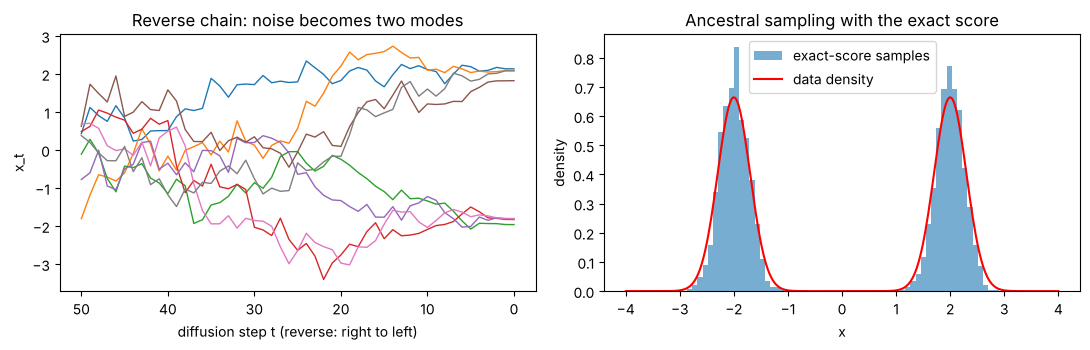

In [14]:
def score_marginal(x, t):
    # exact score of q_t(x) = sum_k w_k N(x; sqrt(ab_t) m_k, ab_t s_k^2 + 1 - ab_t)
    means = np.sqrt(alpha_bar[t]) * m_d
    var = alpha_bar[t] * s_d ** 2 + (1 - alpha_bar[t])
    return mixture_score(x, w_d, means, np.sqrt(var))

def eps_from_score(x, t):
    return -np.sqrt(1 - alpha_bar[t]) * score_marginal(x, t)

def ancestral_sample(eps_model, n, rng):
    x = rng.standard_normal(n)                      # x_T ~ N(0, 1)
    for t in range(T - 1, -1, -1):
        eps_hat = eps_model(x, t)
        mean = (x - betas[t] / np.sqrt(1 - alpha_bar[t]) * eps_hat) / np.sqrt(alphas[t])
        if t > 0:
            sigma_t = np.sqrt((1 - alpha_bar[t - 1]) / (1 - alpha_bar[t]) * betas[t])   # beta_tilde_t
            x = mean + sigma_t * rng.standard_normal(n)
        else:
            x = mean                                # no noise at the last step
    return x

x_gen_exact = ancestral_sample(eps_from_score, 4_000, rng)
print(f"samples with the exact score: fraction > 0 = {np.mean(x_gen_exact > 0):.3f} (0.5),  mean |x| = {np.mean(np.abs(x_gen_exact)):.3f} (2.0),  "
      f"sd within the right mode = {x_gen_exact[x_gen_exact > 0].std():.3f} (0.3)")

# the reverse chain, a few trajectories
n_traj = 8
traj = np.empty((T + 1, n_traj)); x = rng.standard_normal(n_traj); traj[T] = x
for t in range(T - 1, -1, -1):
    eps_hat = eps_from_score(x, t)
    mean = (x - betas[t] / np.sqrt(1 - alpha_bar[t]) * eps_hat) / np.sqrt(alphas[t])
    x = mean + (np.sqrt((1 - alpha_bar[t - 1]) / (1 - alpha_bar[t]) * betas[t]) * rng.standard_normal(n_traj) if t > 0 else 0)
    traj[t] = x
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(np.arange(T + 1), traj, lw=1); ax1.invert_xaxis(); ax1.set_xlabel("diffusion step t (reverse: right to left)"); ax1.set_ylabel("x_t"); ax1.set_title("Reverse chain: noise becomes two modes")
grid_x = np.linspace(-4, 4, 300)
ax2.hist(x_gen_exact, bins=60, density=True, alpha=0.6, label="exact-score samples")
ax2.plot(grid_x, 0.5 * stats.norm.pdf(grid_x, -2, 0.3) + 0.5 * stats.norm.pdf(grid_x, 2, 0.3), "r", label="data density")
ax2.set_xlabel("x"); ax2.set_ylabel("density"); ax2.set_title("Ancestral sampling with the exact score"); ax2.legend()
plt.tight_layout(); plt.show()

The one-shot marginal matches the step-by-step chain in mean and variance — that is the closed-form
$q(x_t \mid x_0)$, and it is what makes training cheap (any noise level in one draw). Run backwards with the
exact score, 50 small denoising steps turn standard-normal noise into the two data modes with the right
weights and widths. In a real model the score is not available; the next cell *learns* it.

### Learning the noise predictor

A small MLP $\varepsilon_\theta(x_t, t)$ (inputs: $x_t$ and a sinusoidal embedding of $t$; two hidden layers
of 64 tanh units) is trained on the simplified loss $\mathbb{E}\,\|\varepsilon - \varepsilon_\theta(\sqrt{\bar\alpha_t}x_0 +
\sqrt{1 - \bar\alpha_t}\varepsilon, t)\|^2$: for each mini-batch pick random data points, random steps $t$ and random
noise, corrupt in one shot, regress the noise. Forward and backward passes are written by hand
(Module 16), Adam does the updates.

noise-prediction loss: first 50 steps 0.575  ->  last 200 steps 0.348
samples with the learned denoiser: fraction > 0 = 0.454 (0.5),  mean |x| = 1.960 (2.0),  sd within the right mode = 0.305 (0.3)


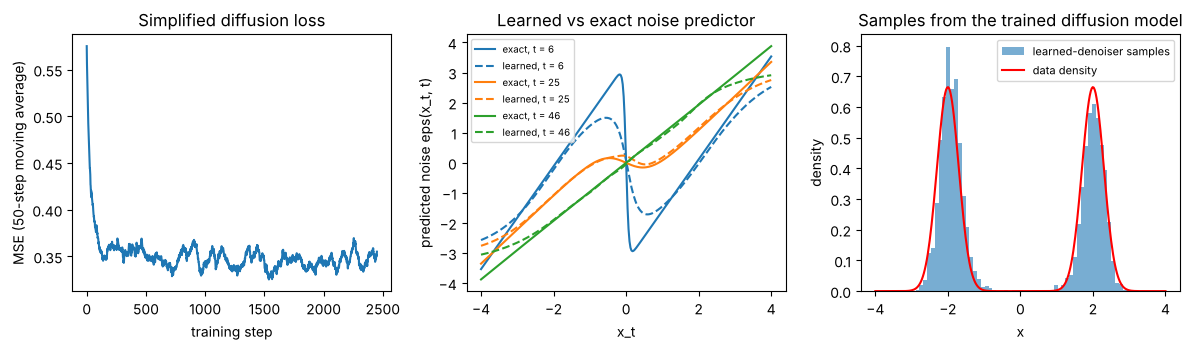

In [15]:
def time_features(x, t):
    tt = (np.asarray(t, dtype=float) + 1) / T
    return np.column_stack([x, tt, np.sin(2 * np.pi * tt), np.cos(2 * np.pi * tt), np.sin(4 * np.pi * tt), np.cos(4 * np.pi * tt)])

H = 64
net = dict(W1=rng.standard_normal((6, H)) / np.sqrt(6), b1=np.zeros(H),
           W2=rng.standard_normal((H, H)) / np.sqrt(H), b2=np.zeros(H),
           W3=rng.standard_normal((H, 1)) / np.sqrt(H), b3=np.zeros(1))

def mlp_forward(p, F):
    h1 = np.tanh(F @ p["W1"] + p["b1"]); h2 = np.tanh(h1 @ p["W2"] + p["b2"])
    return (h2 @ p["W3"] + p["b3"])[:, 0], (F, h1, h2)

def mlp_backward(p, cache, d_out):
    F, h1, h2 = cache; d_out = d_out[:, None]
    g = {"W3": h2.T @ d_out, "b3": d_out.sum(0)}
    d_h2 = (d_out @ p["W3"].T) * (1 - h2 ** 2)
    g["W2"] = h1.T @ d_h2; g["b2"] = d_h2.sum(0)
    d_h1 = (d_h2 @ p["W2"].T) * (1 - h1 ** 2)
    g["W1"] = F.T @ d_h1; g["b1"] = d_h1.sum(0)
    return g

m_net = {k: np.zeros_like(v) for k, v in net.items()}; v_net = {k: np.zeros_like(v) for k, v in net.items()}
batch, losses = 256, []
for it in range(1, 2501):
    idx = rng.integers(0, n_data, batch)
    t_b = rng.integers(0, T, batch)
    eps_b = rng.standard_normal(batch)
    x_t = q_sample(x0[idx], t_b, eps_b)                       # one-shot corruption
    pred, cache = mlp_forward(net, time_features(x_t, t_b))
    losses.append(np.mean((pred - eps_b) ** 2))
    grads = mlp_backward(net, cache, 2 * (pred - eps_b) / batch)
    adam_step(net, grads, m_net, v_net, it, lr=3e-3)
print(f"noise-prediction loss: first 50 steps {np.mean(losses[:50]):.3f}  ->  last 200 steps {np.mean(losses[-200:]):.3f}")

eps_learned = lambda x, t: mlp_forward(net, time_features(x, np.full(len(x), t)))[0]
x_gen_learned = ancestral_sample(eps_learned, 4_000, rng)
print(f"samples with the learned denoiser: fraction > 0 = {np.mean(x_gen_learned > 0):.3f} (0.5),  mean |x| = {np.mean(np.abs(x_gen_learned)):.3f} (2.0),  "
      f"sd within the right mode = {x_gen_learned[x_gen_learned > 0].std():.3f} (0.3)")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].plot(np.convolve(losses, np.ones(50) / 50, mode="valid")); axes[0].set_xlabel("training step"); axes[0].set_ylabel("MSE (50-step moving average)"); axes[0].set_title("Simplified diffusion loss")
for t_show, c in ((5, "C0"), (24, "C1"), (45, "C2")):
    axes[1].plot(grid_x, eps_from_score(grid_x, t_show), c, label=f"exact, t = {t_show + 1}")
    axes[1].plot(grid_x, eps_learned(grid_x, t_show), c + "--", label=f"learned, t = {t_show + 1}")
axes[1].set_xlabel("x_t"); axes[1].set_ylabel("predicted noise eps(x_t, t)"); axes[1].set_title("Learned vs exact noise predictor"); axes[1].legend(fontsize=7)
axes[2].hist(x_gen_learned, bins=60, density=True, alpha=0.6, label="learned-denoiser samples")
axes[2].plot(grid_x, 0.5 * stats.norm.pdf(grid_x, -2, 0.3) + 0.5 * stats.norm.pdf(grid_x, 2, 0.3), "r", label="data density")
axes[2].set_xlabel("x"); axes[2].set_ylabel("density"); axes[2].set_title("Samples from the trained diffusion model"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The learned noise predictor tracks the exact one closely where the data live and deviates only in the far
tails that the training set never visits, and the samples it generates reproduce both modes with
approximately the right weights and widths. The loss cannot go to zero: at high noise levels the noise is
genuinely unpredictable from $x_t$, and the minimum achievable MSE is the posterior variance of
$\varepsilon$ given $x_t$. This is, in miniature, the entire training and sampling loop of a modern image
diffusion model; the differences are a U-Net or transformer in place of the 64-unit MLP, images in place of
scalars, and 1,000 steps in place of 50.

**Try it yourself:** sample with only every 5th step (keep `t` in `range(T-1, -1, -5)` and use
$\bar\alpha$ of the skipped-to step) — ancestral sampling degrades quickly, which is what DDIM's
deterministic update was designed to fix.

## 12. Evaluating generative models: the Fréchet distance between two Gaussians

$\text{FID} = \|\mu_r - \mu_g\|^2 + \operatorname{tr}\big(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\big)$.
We implement it with `scipy.linalg.sqrtm`, verify the hand-worked values ($\mathcal{N}(0,1)$ vs $\mathcal{N}(1,4)$
gives 2; the 2-D example gives 2.25), estimate it from samples in five dimensions, and show the
finite-sample bias: two samples from the *same* distribution do not give zero. Finally we score the two
diffusion samplers of Section 10 against the data.

In [16]:
from scipy import linalg

def frechet_distance(mu1, S1, mu2, S2):
    S1, S2 = np.atleast_2d(S1), np.atleast_2d(S2)
    covmean = np.real(linalg.sqrtm(S1 @ S2))
    return float(np.sum((np.asarray(mu1) - np.asarray(mu2)) ** 2) + np.trace(S1 + S2 - 2 * covmean))

def fid_from_samples(A, B):
    A, B = np.atleast_2d(A.T).T, np.atleast_2d(B.T).T
    return frechet_distance(A.mean(0), np.cov(A.T), B.mean(0), np.cov(B.T))

print(f"N(0,1) vs N(1,4): {frechet_distance([0.0], [[1.0]], [1.0], [[4.0]]):.4f}   (hand: 1 + 1 = 2)")
print(f"2-D example:      {frechet_distance([0, 0], np.eye(2), [1, 0.5], np.diag([4.0, 1.0])):.4f}   (hand: 1.25 + 1 = 2.25)")

d = 5
A = rng.multivariate_normal(np.zeros(d), np.eye(d), 5_000)
B = rng.multivariate_normal(0.5 * np.ones(d), 1.5 * np.eye(d), 5_000)
A2 = rng.multivariate_normal(np.zeros(d), np.eye(d), 5_000)
print(f"5-D from 5,000 samples each: {fid_from_samples(A, B):.4f}   exact {frechet_distance(np.zeros(d), np.eye(d), 0.5 * np.ones(d), 1.5 * np.eye(d)):.4f}")
print(f"two samples from the SAME distribution: {fid_from_samples(A, A2):.4f}  (not zero: finite-sample bias)")
for n_s in (100, 1_000, 5_000):
    vals = [fid_from_samples(rng.standard_normal((n_s, d)), rng.standard_normal((n_s, d))) for _ in range(20)]
    print(f"   same-distribution FID with n = {n_s:>5d}: mean {np.mean(vals):.4f}")

# score the diffusion samplers against held-out data (1-D, so 'features' are the raw values)
x_test = np.where(rng.random(4_000) < 0.5, -2.0, 2.0) + 0.3 * rng.standard_normal(4_000)
print(f"\n1-D Frechet distance to fresh data: exact-score sampler {fid_from_samples(x_test[:, None], x_gen_exact[:, None]):.4f},"
      f"  learned denoiser {fid_from_samples(x_test[:, None], x_gen_learned[:, None]):.4f},  pure noise N(0,1) {fid_from_samples(x_test[:, None], rng.standard_normal(4_000)[:, None]):.4f}")

N(0,1) vs N(1,4): 2.0000   (hand: 1 + 1 = 2)
2-D example:      2.2500   (hand: 1.25 + 1 = 2.25)
5-D from 5,000 samples each: 1.4420   exact 1.5026
two samples from the SAME distribution: 0.0060  (not zero: finite-sample bias)
   same-distribution FID with n =   100: mean 0.2895
   same-distribution FID with n =  1000: mean 0.0235
   same-distribution FID with n =  5000: mean 0.0046

1-D Frechet distance to fresh data: exact-score sampler 0.0008,  learned denoiser 0.0184,  pure noise N(0,1) 1.0220


The formula reproduces the hand calculations exactly and recovers the true distance from samples to two
decimals, but two samples from the same distribution score a small positive number that shrinks like
$1/n$ — always compare models at the same sample size. Both diffusion samplers score far below the
pure-noise baseline; the exact-score sampler is better than the learned one, as it should be. Note what the
metric does *not* see: a Gaussian fit cannot tell a two-mode distribution from a one-mode one with the same
mean and variance, which is why precision/recall-style metrics exist alongside FID.

## Summary

- Any expectation becomes an average with error $\sigma_f/\sqrt{n}$ once you can sample from $p$; the module is about making "$X_i \sim p$" true.
- Uniforms are turned into exact samples by the inverse CDF, cumulative sums (the LLM decoder), Box–Muller and the reparameterisation $\mu + \sigma z$.
- Rejection sampling is exact with acceptance rate $1/M$ and collapses like $\sigma^{-d}$ in high dimension; importance sampling reweights instead, and its ESS $(\sum w)^2/\sum w^2$ is the diagnostic that catches light-tailed proposals.
- A Markov chain's stationary distribution solves $\pi = \pi P$; detailed balance implies stationarity (not conversely), and $|\lambda_2|$ sets the mixing speed.
- Metropolis–Hastings accepts with $\min\{1, \tilde p(x')q(x \mid x')/(\tilde p(x)q(x' \mid x))\}$ and satisfies detailed balance for any $\tilde p$; tune the step for 0.2–0.5 acceptance and judge by autocorrelation and ESS, never by acceptance rate alone.
- Gibbs updates exact conditionals (acceptance 1) but crawls along correlated ridges ($\rho_k = \rho^{2k}$); Langevin dynamics is gradient ascent on $\log p$ plus noise of variance $\epsilon$ and needs only the score.
- The ELBO is a lower bound on $\log p(x)$ whose gap is $\text{KL}(q \,\|\, p(z \mid x))$ — mode-seeking; the pathwise gradient has far lower variance than the score-function gradient.
- A VAE minimises reconstruction $+ \frac12\sum(\mu^2 + \sigma^2 - 1 - \log\sigma^2)$ through one reparameterised sample; the linear case is probabilistic PCA.
- Diffusion: $q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar\alpha_t}x_0, (1 - \bar\alpha_t)I)$, train on $\|\varepsilon - \varepsilon_\theta(x_t, t)\|^2$, sample by iterated denoising; the noise predictor is the score and each reverse step is a Langevin step.
- FID is the Wasserstein-2 distance between Gaussian fits in feature space; it is biased at small $n$ and blind to anything beyond means and covariances.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.